In [3]:
!pip install kagglehub torch torchvision matplotlib seaborn scikit-learn tqdm

In [4]:
import os
import copy
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from torchvision.models import ResNet18_Weights

from sklearn.metrics import classification_report, confusion_matrix
from tqdm import tqdm

from sklearn.metrics import f1_score

In [5]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [6]:
from PIL import ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

In [8]:
import kagglehub

path = kagglehub.dataset_download("maysee/mushrooms-classification-common-genuss-images")

print(path)

Using Colab cache for faster access to the 'mushrooms-classification-common-genuss-images' dataset.
/kaggle/input/mushrooms-classification-common-genuss-images


In [9]:
for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        for file in files[:5]:
            print("  " * (level + 1) + file)

    if level >= 2:
        dirs[:] = []

mushrooms-classification-common-genuss-images/
  Mushrooms/
    Entoloma/
      126_-P40YY9dxnU.jpg
      092_C-d5aHykeOY.jpg
      033_yJBfhGv9URU.jpg
      154_HDT_he4bSpA.jpg
      159_gzyo4cu2SF0.jpg
    Suillus/
      168_nQy5xpC7tWk.jpg
      000_o5wtwaqK-UE.jpg
      317_41mNOdPZlRo.jpg
      244_wFrkfThPI18.jpg
      139_I8Oaix9-ru4.jpg
    Hygrocybe/
      159_Ymge5g1qpP4.jpg
      320_M-2ZFAkYh4I.jpg
      219_TNCiivIfrJo.jpg
      325_rro3hIu1Nqw.jpg
      257_LPbsa5Oitj0.jpg
    Agaricus/
      240_dHmH11hDvVw.jpg
      017_QHGfbEiWvq8.jpg
      230_3LvVAPLp6L0.jpg
      009_mrv34Sn4WiQ.jpg
      388_T-pbnIiXSkw.jpg
    Amanita/
      015_kiug4wB91So.jpg
      156_FSY4lXLnMTI.jpg
      413_szlg7TD0TDs.jpg
      508_DMB-oiAz_yg.jpg
      375_P-BLH48Oaaw.jpg
    Lactarius/
      0510_2IIoEnw3Wqc.jpg
      123_pvL1IvRrvWQ.jpg
      0606_RAN_iv0BSus.jpg
      0772_5e2SrIds9Gg.jpg
      0340_0gzvFhGVf5M.jpg
    Russula/
      339_EYXm1gIy6fU.jpg
      108_2muj33rTLeM.jpg
      4

In [10]:
data_dir = os.path.join(path, "Mushrooms")
print(data_dir)

/kaggle/input/mushrooms-classification-common-genuss-images/Mushrooms


In [11]:
weights = ResNet18_Weights.DEFAULT

val_transform = weights.transforms()

train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [12]:
dataset = datasets.ImageFolder(root=data_dir, transform=val_transform)

classes = dataset.classes
num_classes = len(classes)

print("Количество изображений:", len(dataset))
print("Количество классов:", num_classes)
print("Классы:", classes)

Количество изображений: 6714
Количество классов: 9
Классы: ['Agaricus', 'Amanita', 'Boletus', 'Cortinarius', 'Entoloma', 'Hygrocybe', 'Lactarius', 'Russula', 'Suillus']


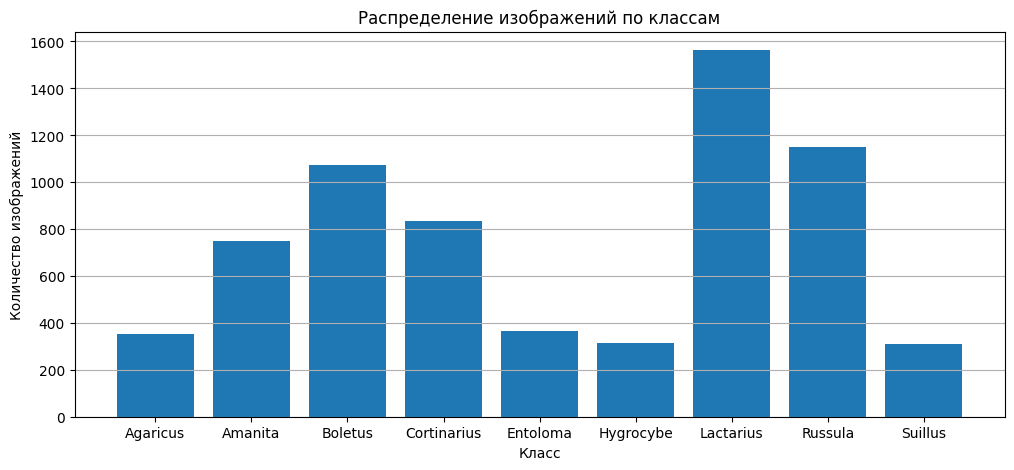

In [14]:
class_counts = np.bincount(dataset.targets)

plt.figure(figsize=(12, 5))
plt.bar(classes, class_counts)
plt.xlabel("Класс")
plt.ylabel("Количество изображений")
plt.title("Распределение изображений по классам")
plt.grid(axis="y")
plt.show()

In [15]:
train_dataset = datasets.ImageFolder(root=data_dir, transform=train_transform)

test_dataset = datasets.ImageFolder(root=data_dir, transform=val_transform)

assert train_dataset.classes == test_dataset.classes

from sklearn.model_selection import train_test_split

indices = np.arange(len(dataset))
targets = np.array(dataset.targets)

# Отношение тестовая выборка/обучающая выборка = 1/4
train_indices, test_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=SEED,
    stratify=targets
)

train_data = Subset(train_dataset, train_indices)
test_data = Subset(test_dataset, test_indices)

print("Обучающая выборка:", len(train_data))
print("Тестовая выборка:", len(test_data))

Обучающая выборка: 5371
Тестовая выборка: 1343


In [18]:
BATCH_SIZE = 32

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

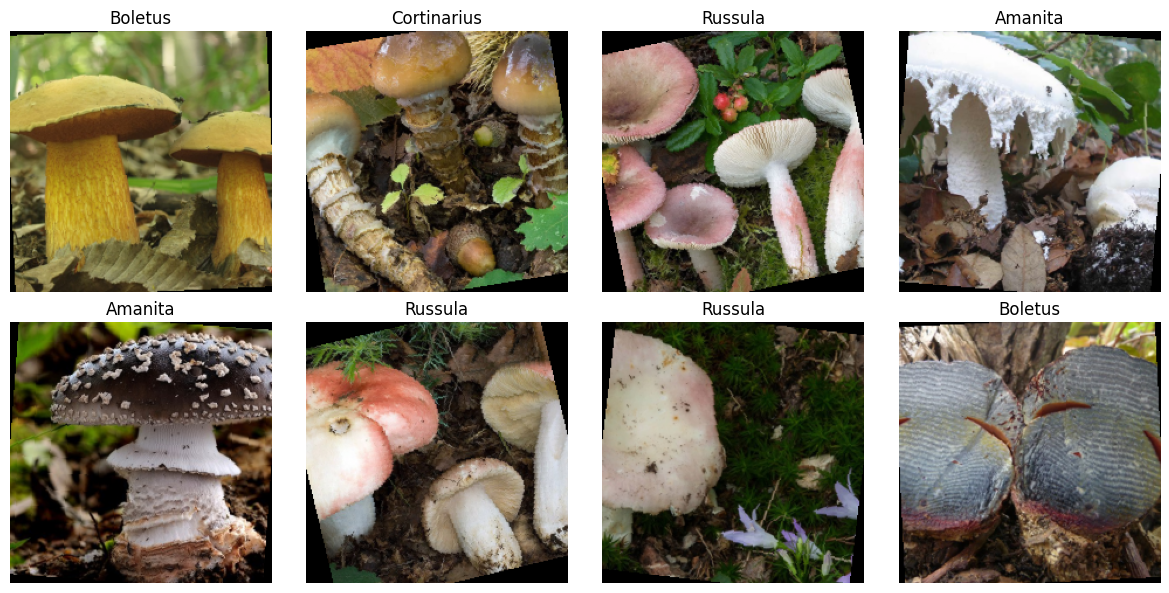

In [21]:
def show_images(dataset, classes, count=8):
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))

    indices = random.sample(range(len(dataset)), count)

    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    for ax, idx in zip(axes.flat, indices):
        image, label = dataset[idx]
        image = image * std + mean
        image = image.permute(1, 2, 0).clamp(0, 1)

        ax.imshow(image)
        ax.set_title(classes[label])
        ax.axis("off")

    plt.tight_layout()
    plt.show()


show_images(train_data, classes)

In [22]:
model = models.resnet18(weights=weights)

# заменяем последний слой на нужное нам количество классов = 9
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, num_classes)
model = model.to(device)

print(model)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 138MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [24]:
NUM_EPOCHS = 30
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

In [27]:
def train_model(model, train_loader, test_loader, criterion, optimizer, num_epochs, device):
    train_loss_history = []
    test_loss_history = []

    train_acc_history = []
    test_acc_history = []

    train_f1_history = []
    test_f1_history = []

    for epoch in range(num_epochs):
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        all_predictions = []
        all_labels = []

        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}")
        for images, labels in pbar:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_predictions.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

            current_loss = running_loss / total
            current_acc = correct / total

            current_f1 = f1_score(all_labels, all_predictions, average='macro', zero_division=0)

            pbar.set_postfix({
                "Loss": f"{current_loss:.4f}",
                "Accuracy": f"{current_acc * 100:.2f}%",
                "F1": f"{current_f1:.4f}"
            })

        epoch_train_loss = running_loss / total
        epoch_train_acc = correct / total

        epoch_train_f1 = f1_score(all_labels, all_predictions, average='macro', zero_division=0)

        model.eval()

        running_loss = 0.0
        correct = 0
        total = 0

        all_predictions = []
        all_labels = []

        with torch.no_grad():
            pbar = tqdm(test_loader, desc="Testing")
            for images, labels in pbar:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                running_loss += loss.item() * images.size(0)

                _, predicted = torch.max(outputs, 1)

                total += labels.size(0)
                correct += (predicted == labels).sum().item()

                all_predictions.extend(predicted.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

                current_loss = running_loss / total
                current_acc = correct / total

                current_f1 = f1_score(all_labels, all_predictions, average='macro', zero_division=0)

                pbar.set_postfix({
                    "Loss": f"{current_loss:.4f}",
                    "Accuracy": f"{current_acc * 100:.2f}%",
                    "F1": f"{current_f1:.4f}"
                })

        epoch_test_loss = running_loss / total
        epoch_test_acc = correct / total

        epoch_test_f1 = f1_score(all_labels, all_predictions, average='macro', zero_division=0)

        train_loss_history.append(epoch_train_loss)
        test_loss_history.append(epoch_test_loss)

        train_acc_history.append(epoch_train_acc)
        test_acc_history.append(epoch_test_acc)

        train_f1_history.append(epoch_train_f1)
        test_f1_history.append(epoch_test_f1)

        print(
            f"Train Loss: {epoch_train_loss:.4f} "
            f"Train Accuracy: {epoch_train_acc * 100:.2f}% "
            f"Train F1: {epoch_train_f1:.4f} "
            f"Test Loss: {epoch_test_loss:.4f} "
            f"Test Accuracy: {epoch_test_acc * 100:.2f}% "
            f"Test F1: {epoch_test_f1:.4f}\n"
        )

    return (train_loss_history, test_loss_history, train_acc_history, test_acc_history, train_f1_history, test_f1_history)


In [28]:
train_loss, test_loss, train_acc, test_acc, train_f1, test_f1 = train_model(model, train_loader, test_loader, criterion, optimizer, NUM_EPOCHS, device)

Testing: 100%|██████████| 42/42 [00:15<00:00,  2.65it/s, Loss=0.4461, Accuracy=84.81%, F1=0.8391]


Train Loss: 0.3021 Train Accuracy: 90.86% Train F1: 0.8990 Test Loss: 0.4461 Test Accuracy: 84.81% Test F1: 0.8391



Testing: 100%|██████████| 42/42 [00:15<00:00,  2.66it/s, Loss=0.3670, Accuracy=87.27%, F1=0.8498]


Train Loss: 0.1938 Train Accuracy: 94.00% Train F1: 0.9357 Test Loss: 0.3670 Test Accuracy: 87.27% Test F1: 0.8498



Testing: 100%|██████████| 42/42 [00:17<00:00,  2.46it/s, Loss=0.3599, Accuracy=88.38%, F1=0.8720]


Train Loss: 0.1268 Train Accuracy: 96.18% Train F1: 0.9575 Test Loss: 0.3599 Test Accuracy: 88.38% Test F1: 0.8720



... (50 outputs left out)

Testing: 100%|██████████| 42/42 [00:16<00:00,  2.51it/s, Loss=0.3782, Accuracy=89.72%, F1=0.8864]


Train Loss: 0.0149 Train Accuracy: 99.57% Train F1: 0.9963 Test Loss: 0.3782 Test Accuracy: 89.72% Test F1: 0.8864



Testing: 100%|██████████| 42/42 [00:17<00:00,  2.40it/s, Loss=0.4333, Accuracy=88.98%, F1=0.8823]

Train Loss: 0.0157 Train Accuracy: 99.53% Train F1: 0.9955 Test Loss: 0.4333 Test Accuracy: 88.98% Test F1: 0.8823



In [29]:
def print_history(train, test, title):
  plt.figure(figsize = (7, 4))
  plt.plot(train, label="Train")
  plt.plot(test, label="Test")
  plt.grid(True, which = 'both')
  plt.legend()
  plt.xlabel("Число эпох")
  plt.ylabel(title)

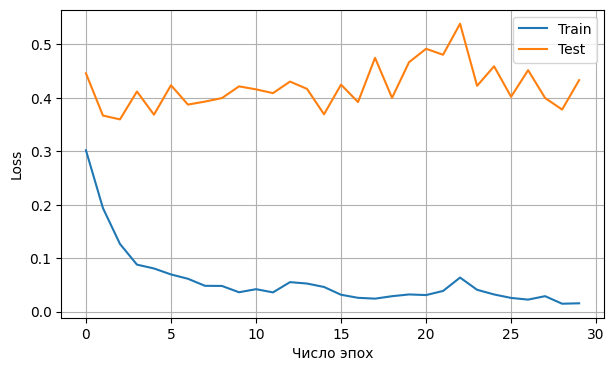

In [30]:
print_history(train_loss, test_loss, "Loss")

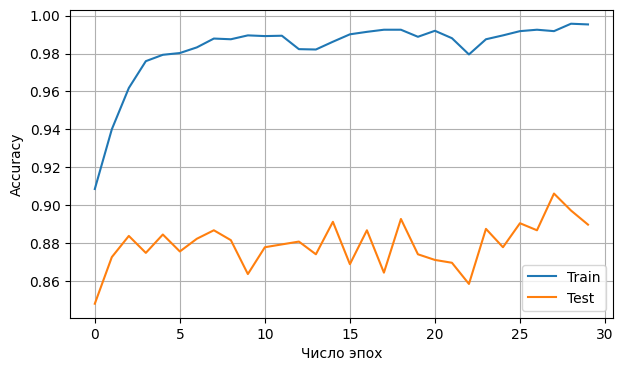

In [31]:
print_history(train_acc, test_acc, "Accuracy")

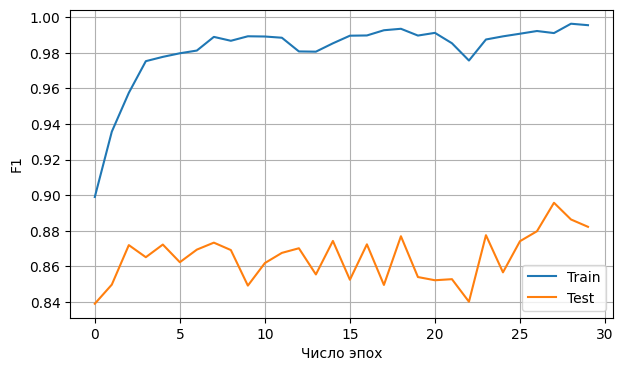

In [32]:
print_history(train_f1, test_f1, "F1")